# From College to Independence · Visual analysis

Select the project Python interpreter to rerun the notebook in VS Code. The figures use the packaged results in `final/outputs/`.

The main model uses local pay for each city and occupation. The entry-signal variant uses regional pay for each occupation. Both report modeled combinations. Set `salary_model` in the first code cell to switch the heatmap and equity chart.

In [1]:
from io import BytesIO
from pathlib import Path

from IPython.display import Image, display
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FuncFormatter, PercentFormatter
import pandas as pd

project = next(
    (root / folder for root in (Path.cwd(), *Path.cwd().parents)
     for folder in (".", "final")
     if (root / folder / "outputs/market_inputs/salary_by_occupation.csv").is_file()),
    None,
)
if project is None:
    raise FileNotFoundError("Run final/run_pipeline.py, then open this notebook from datathon or final.")

import sys
sys.path.insert(0, str(project.resolve()))
from src.results import table_path

salary_model = "city_occupation"  # Use "entry_signal" for regional entry-signal estimates.
suffix = {"city_occupation": "", "entry_signal": "_entry_signal"}[salary_model]

def read(name):
    return pd.read_csv(table_path(project / "outputs", f"{name}.csv"))

def show(fig):
    stream = BytesIO()
    fig.savefig(stream, format="png", dpi=135, bbox_inches="tight", facecolor="white")
    display(Image(data=stream.getvalue(), format="png"))
    plt.close(fig)

def money(value, _position=None):
    return ("−" if value < 0 else "") + f"${abs(value):,.0f}"

def profile_name(profile):
    if profile.startswith("student_parent"):
        return "Student parent"
    debt, housing, _support = profile.split(" | ")
    labels = {"none_debt": "No debt", "median_debt": "Median debt", "high_debt": "High debt"}
    return f"{labels[debt]}, {housing}"

plt.style.use("seaborn-v0_8-whitegrid")
cash = FuncFormatter(money)
teal, rust, slate = "#14756e", "#A64B30", "#526889"
results = read("combination_results" + suffix)
equity = read("equity_table" + suffix)


## 1. Monthly asking rents

The dots show the median for a one-bedroom unit. The lines span the 25th to 75th percentiles. Labels show the number of distinct combinations of listing attributes behind the sample threshold. The figure shows the 12 city groups with the most such combinations among groups that meet the threshold.

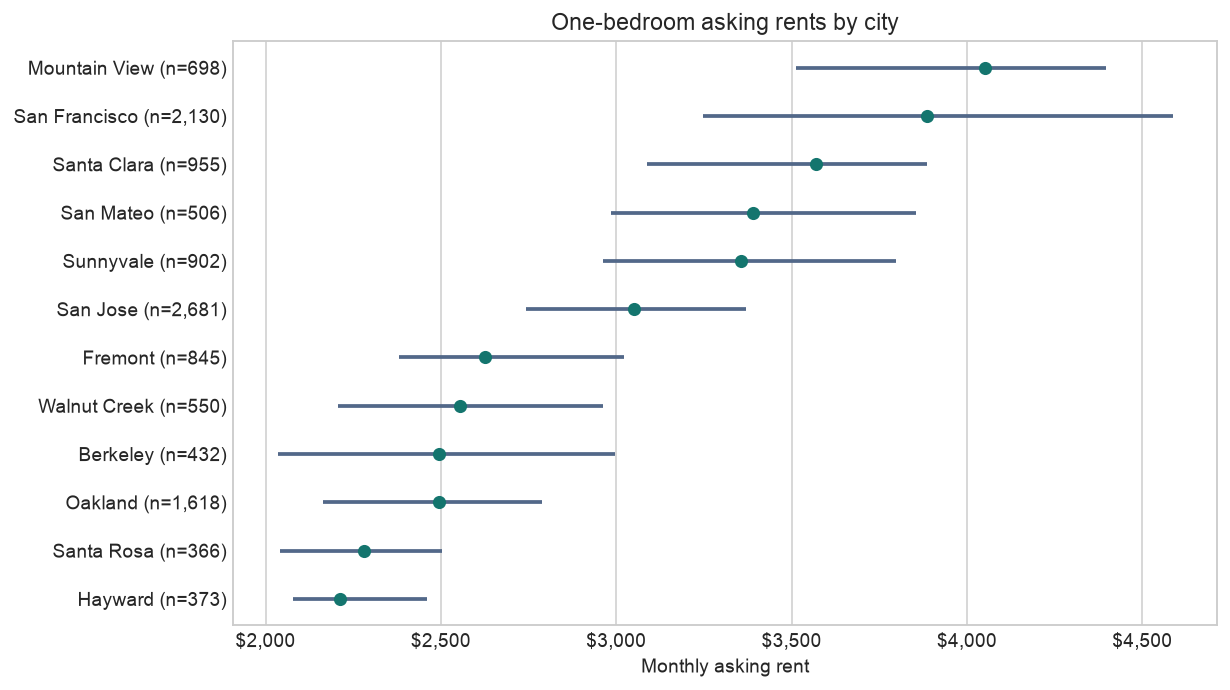

In [2]:
rents = read("rent_by_city_housing")
min_listings = 20
housing_type = "1br"
market = (rents[rents.housing_type.eq(housing_type) & rents.n_valid_rent.ge(min_listings)]
          .nlargest(12, "n_valid_rent").sort_values("median_monthly_rent"))
y = range(len(market))
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.hlines(y, market.rent_q1, market.rent_q3, color=slate, linewidth=2)
ax.scatter(market.median_monthly_rent, y, color=teal, s=36, zorder=3)
ax.set_yticks(list(y), [f"{r.city} (n={r.n_valid_rent:,})" for r in market.itertuples()])
ax.xaxis.set_major_formatter(cash)
ax.set(xlabel="Monthly asking rent", title="One-bedroom asking rents by city")
ax.grid(axis="y", alpha=0)
show(fig)

## 2. Monthly budget gap by city and occupation

Positive values indicate a shortfall after savings. The chart shows up to 15 eligible cities with the most one-bedroom listings for the selected profile. Blank cells indicate insufficient modeled data.

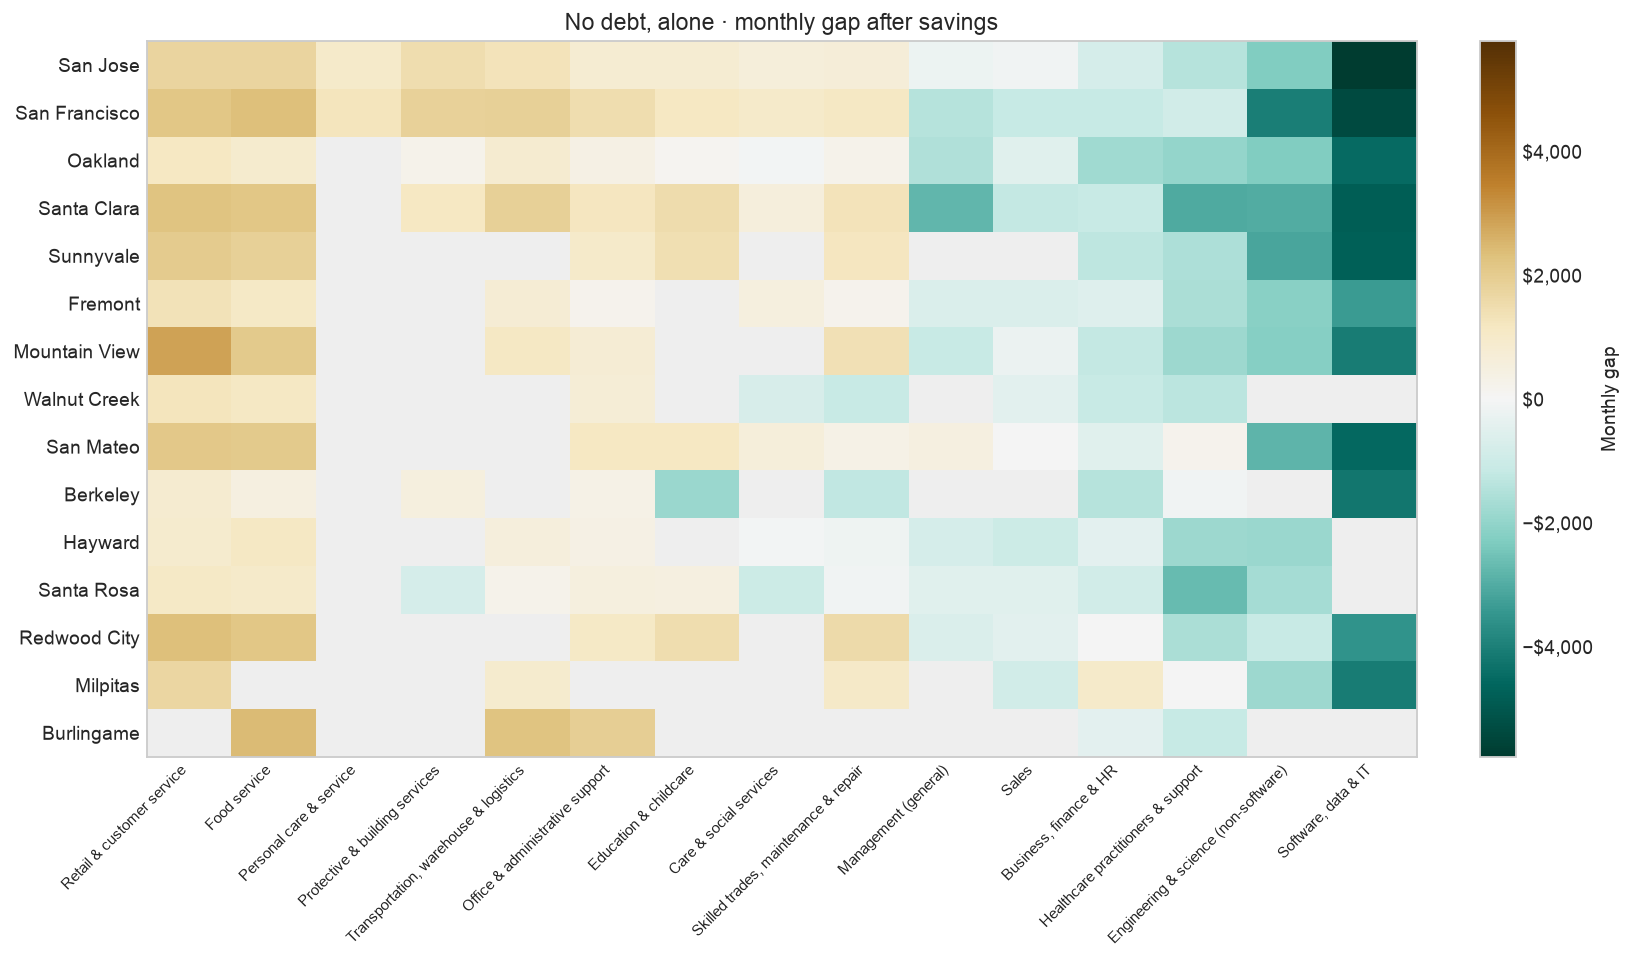

In [3]:
import numpy as np

scenario = "none_debt | alone | no_support"
rows = results[results.profile.eq(scenario)]
city_order = (read("city_opportunity").loc[lambda d: d.city.isin(rows.city)]
              .nlargest(15, "n_valid_rent_1br").city)
order = read("salary_by_occupation").occupation
gap = rows[rows.city.isin(city_order)].pivot(index="city", columns="occupation", values="feasibility_gap")
gap = gap.reindex(index=city_order, columns=[name for name in order if name in gap])
if not gap.notna().any().any():
    raise ValueError("No modeled city and occupation values for the selected profile.")
bound = max(1, float(gap.abs().max().max()))
fig, ax = plt.subplots(figsize=(12, 7), layout="constrained")
palette = plt.colormaps["BrBG_r"].with_extremes(bad="#eeeeee")
heat = ax.imshow(np.ma.masked_invalid(gap.to_numpy()), aspect="auto", cmap=palette,
                 norm=TwoSlopeNorm(vmin=-bound, vcenter=0, vmax=bound))
ax.grid(False)
ax.set_xticks(range(len(gap.columns)), gap.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(gap)), list(gap.index))
fig.colorbar(heat, ax=ax, format=cash, label="Monthly gap")
ax.set_title(f"{profile_name(scenario)} · monthly gap after savings")
show(fig)

## 3. Share of scenarios that fall short

The percentage uses the same eligible city and occupation pairs for every household profile within the selected model.

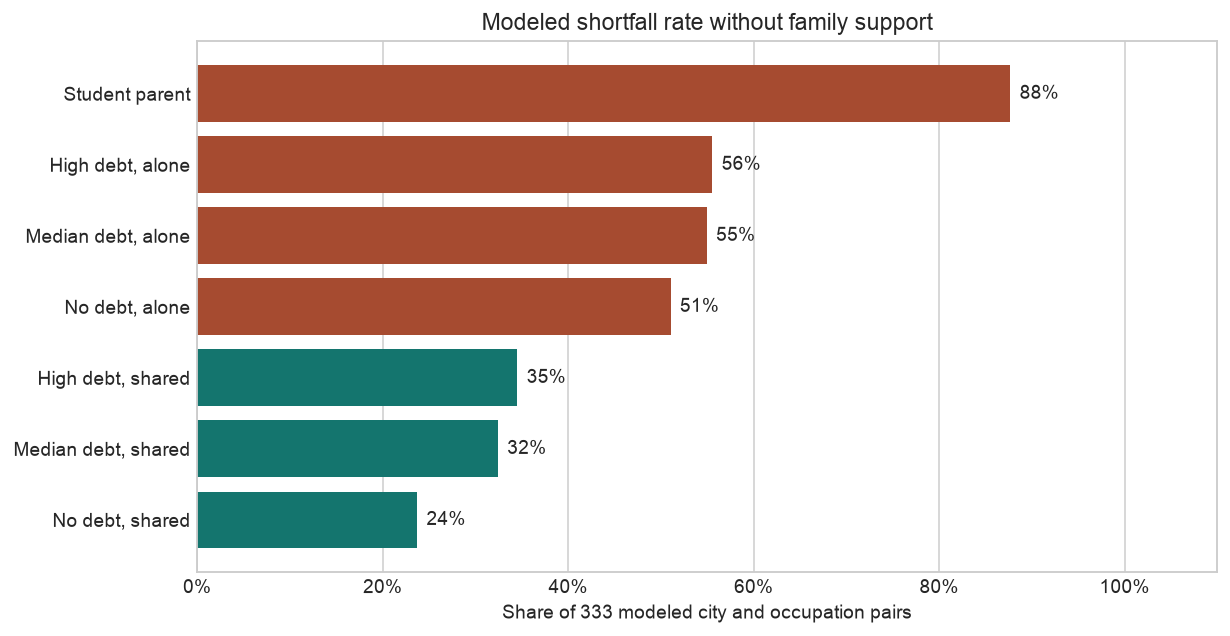

In [4]:
independent = equity[equity.index_type.eq("independence")].sort_values("barrier_index")
labels = independent.profile.map(profile_name)
fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
bars = ax.barh(labels, independent.barrier_index * 100, color=[
    teal if "shared" in profile else rust for profile in independent.profile
])
ax.bar_label(bars, labels=[f"{value:.0%}" for value in independent.barrier_index], padding=5)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set(xlim=(0, 110), xlabel=f"Share of {int(independent.n_combinations.iloc[0])} modeled city and occupation pairs",
       title="Modeled shortfall rate without family support")
ax.grid(axis="y", alpha=0)
show(fig)

## 4. Same pay, different starting points

This fixed city and occupation example uses the main model and zero family support. The bars include the savings target.

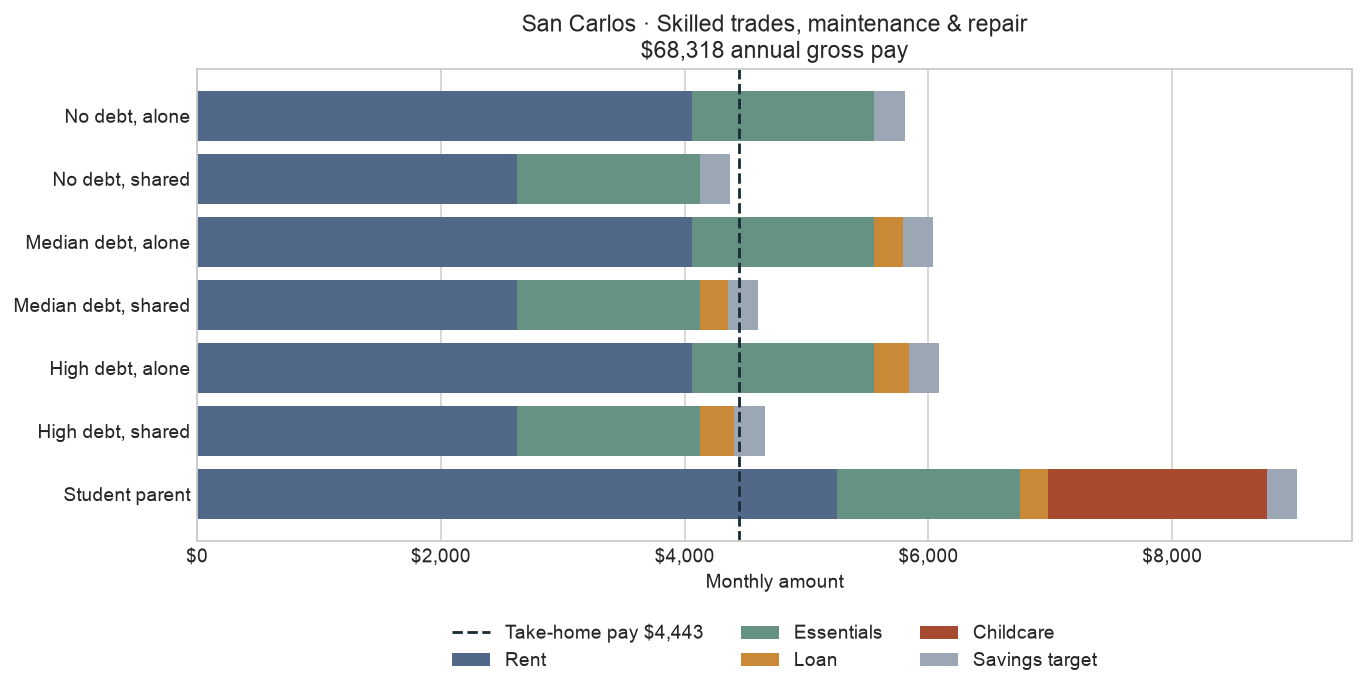

In [5]:
same = read("same_job_different_start")
same = same[same.family_support.eq(0)].copy()
same["label"] = same.profile.map(profile_name)
components = {"personal_rent": ("Rent", slate), "essentials": ("Essentials", "#659283"),
              "loan_payment": ("Loan", "#C98937"), "childcare": ("Childcare", rust),
              "savings_target": ("Savings target", "#9CA7B5")}
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
left = pd.Series(0.0, index=same.index)
for field, (label, color) in components.items():
    ax.barh(same.label, same[field], left=left, label=label, color=color)
    left += same[field]
take_home = same.net_monthly.iloc[0]
ax.axvline(take_home, color="#172D36", linestyle="--", label=f"Take-home pay {money(take_home)}")
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
ax.xaxis.set_major_formatter(cash)
ax.grid(axis="y", alpha=0)
ax.set(xlabel="Monthly amount", title=f"{same.city.iloc[0]} · {same.occupation.iloc[0]}\n{money(same.median_annual_salary.iloc[0])} annual gross pay")
show(fig)

## 5. College net price by reported family-income ceiling

Institution medians are unweighted and cover four-year schools. Counts in the table show how many schools reported a value in each region and income band.

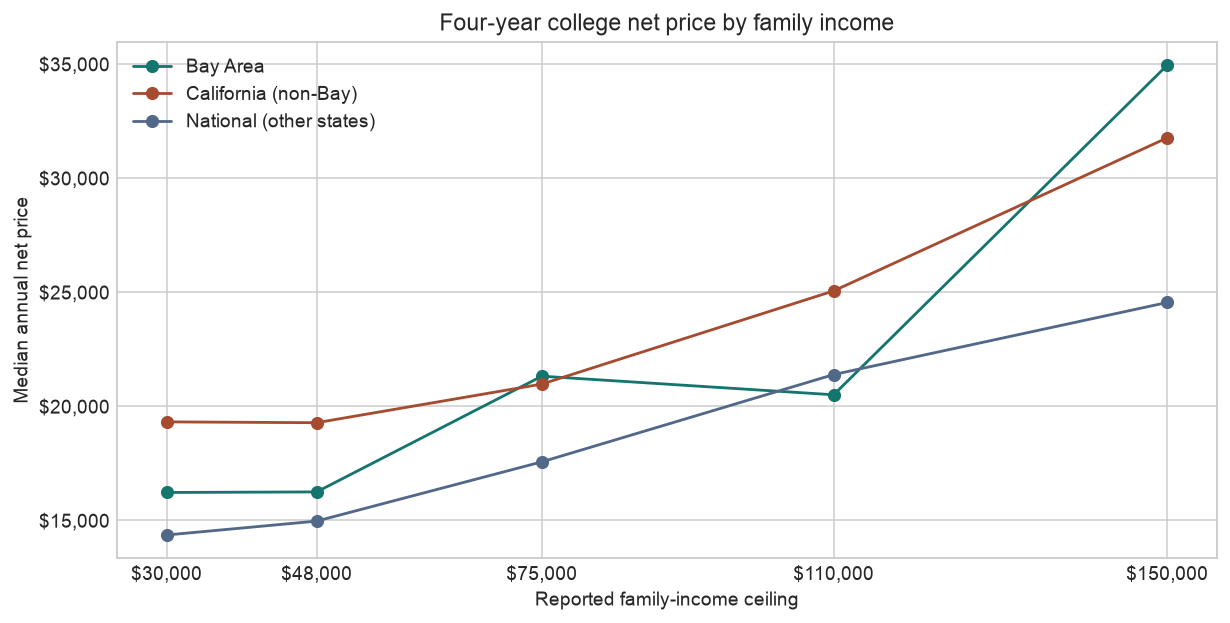

family_income_ceiling_usd,"$30,000","$48,000","$75,000","$110,000","$150,000"
group,,,,,
Bay Area,22,22,22,21,21
California (non-Bay),136,127,122,111,110
National (other states),1956,1889,1862,1777,1632


In [6]:
college = read("college_comparison")
values = college.loc[college.source_column.eq("net_price_2022_23_usd")].dropna(
    subset=["family_income_ceiling_usd", "median", "n_institutions"]
)
if values.empty:
    raise ValueError("No 2022–23 net-price records by family income in college_comparison.csv.")
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
for color, (region, rows) in zip((teal, rust, slate), values.groupby("group", sort=False)):
    rows = rows.sort_values("family_income_ceiling_usd")
    ax.plot(rows.family_income_ceiling_usd, rows["median"], marker="o", label=region, color=color)
bands = sorted(values.family_income_ceiling_usd.unique())
ax.set_xticks(bands, [money(value) for value in bands])
ax.yaxis.set_major_formatter(cash)
ax.set(xlabel="Reported family-income ceiling", ylabel="Median annual net price",
       title="Four-year college net price by family income")
ax.legend(frameon=False)
show(fig)
display(values.pivot(index="group", columns="family_income_ceiling_usd", values="n_institutions")
        .rename(columns=lambda value: money(value)))

## 6. Housing arrangements by occupation

Counts are modeled cities for each occupation. Profiles in this comparison have no debt and receive no family support.

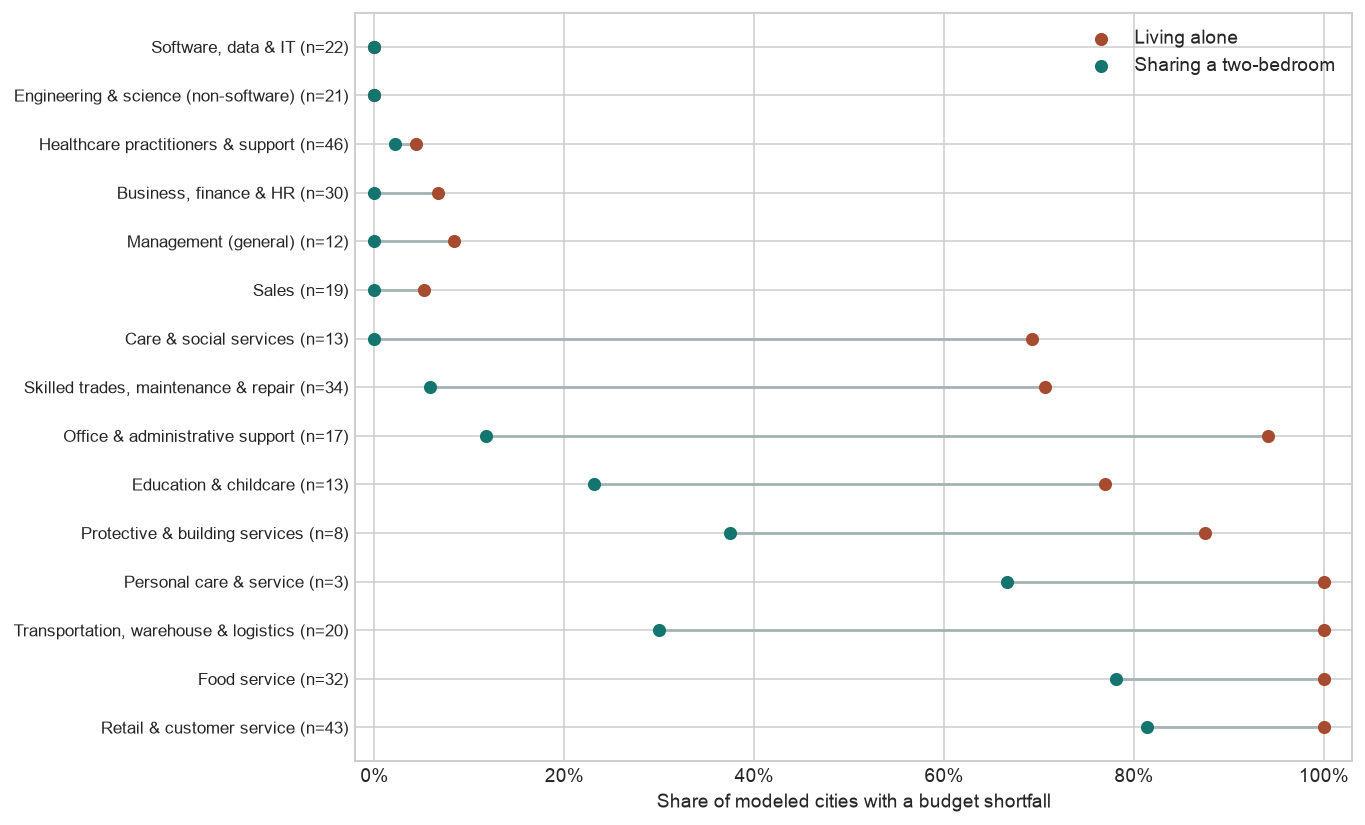

In [7]:
subset = read("occupation_barrier")
prefix = "Bay-Area-wide entry" if suffix else "city x occupation"
subset = subset[subset.pay_definition.str.startswith(prefix)].sort_values("median_salary")
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
y = range(len(subset))
ax.scatter(subset.barrier_alone_no_debt, y, color=rust, label="Living alone", zorder=3)
ax.scatter(subset.barrier_shared_no_debt, y, color=teal, label="Sharing a two-bedroom", zorder=3)
ax.hlines(y, subset.barrier_shared_no_debt, subset.barrier_alone_no_debt, color="#a6b5b4")
ax.set_yticks(list(y), [f"{r.occupation} (n={r.n_cities})" for r in subset.itertuples()], fontsize=9)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set(xlabel="Share of modeled cities with a budget shortfall", xlim=(-.02,1.03))
ax.legend(frameon=False)
show(fig)

## 7. Break-even salary by city

Gross annual pay needed to cover rent, essentials and the savings target with no debt and no family support. The shaded band is the middle 50% of non-senior advertised pay and the line is its median. The chart shows the 20 cities with the most one-bedroom listings.

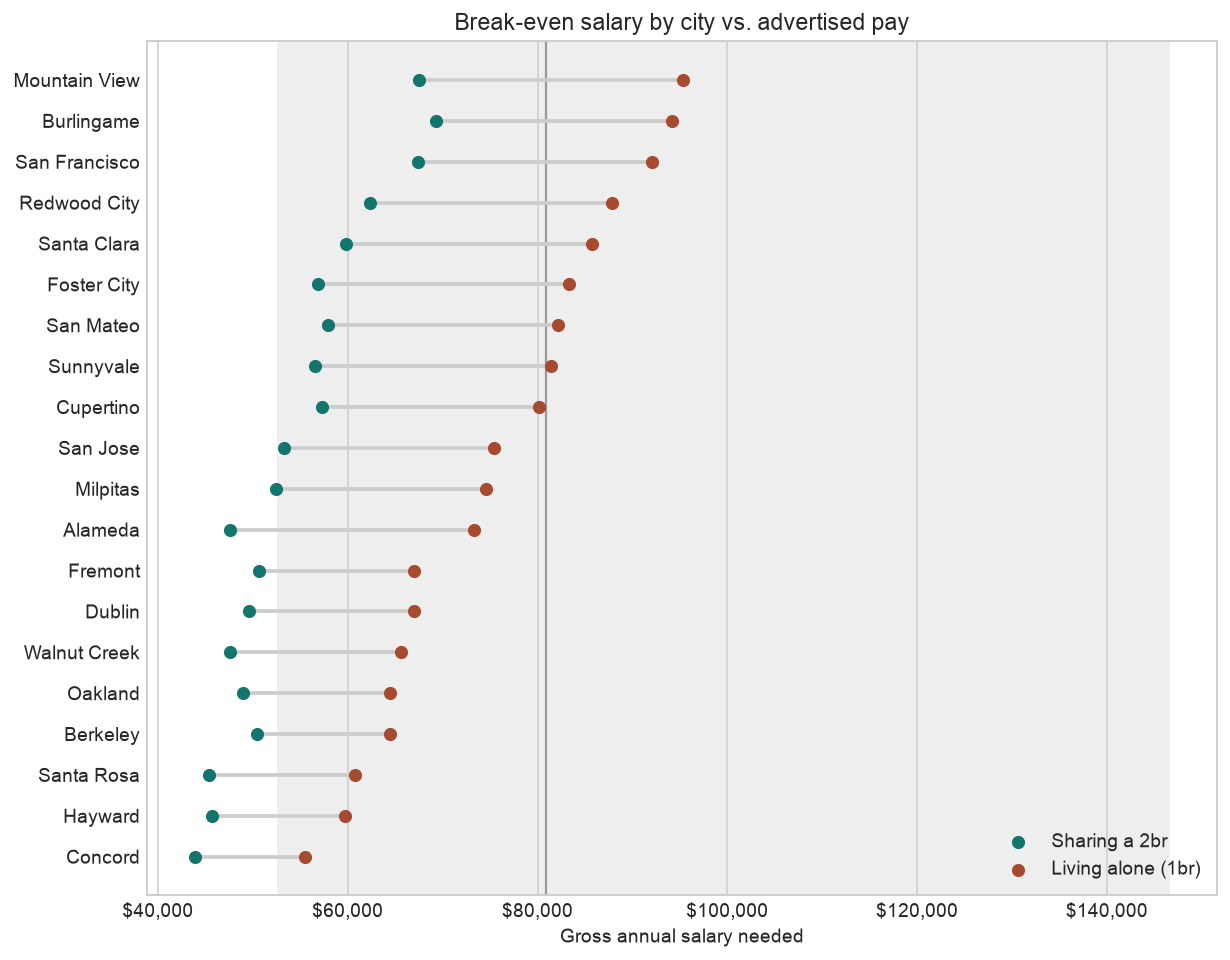

In [8]:
opportunity = read("city_opportunity")
pay = read("salary_levels").set_index("salary_level")["annual_pay_usd"]
top_cities = 20
cities = opportunity.nlargest(top_cities, "n_valid_rent_1br").sort_values("break_even_alone")
y = range(len(cities))
fig, ax = plt.subplots(figsize=(9, 7), layout="constrained")
ax.axvspan(pay["pay_P25"], pay["pay_P75"], color="#eeeeee", zorder=0)
ax.axvline(pay["pay_P50"], color="#999999", linewidth=1.2, zorder=1)
ax.hlines(y, cities.break_even_shared, cities.break_even_alone, color="#cccccc", linewidth=2, zorder=2)
ax.scatter(cities.break_even_shared, y, color=teal, s=36, zorder=3, label="Sharing a 2br")
ax.scatter(cities.break_even_alone, y, color=rust, s=36, zorder=3, label="Living alone (1br)")
ax.set_yticks(list(y), list(cities.city))
ax.xaxis.set_major_formatter(cash)
ax.set(xlabel="Gross annual salary needed", title="Break-even salary by city vs. advertised pay")
ax.grid(axis="y", alpha=0)
ax.legend(loc="lower right", frameon=False)
show(fig)
